# Is the architecture wrong, or only the training data?

The published half-life models are small estimators on top of a frozen representation
backbone, fitted on 130 records. A weak result on our cohort therefore has two possible
causes: the architecture cannot represent peptide stability, or its training set does not
cover our measurement condition.

This notebook separates the two. The backbone stays frozen and the **same estimator
families** are refitted on our human-serum cohort under a sequence-similarity split. This
is the only notebook in the module that fits anything, and every number here describes
our own fit, not a published model.

A similarity split is used rather than a random one because the cohort contains analogue
series; a random split over analogues reports an optimistic figure.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/model_benchmark").is_dir())
sys.path.insert(0, str(ROOT / "src"))

%matplotlib inline
import numpy as np
import pandas as pd
from IPython.display import display
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

In [2]:
from model_benchmark import refit, report
from model_benchmark.config import PRIMARY_COHORT
from model_benchmark.dataset import load_cohort

## REMARK: Two cohorts are refitted. The primary one answers the question for the
## condition we care about; the wider serum-and-plasma cohort doubles the sample and
## shows whether the limiting factor is the amount of data or the representation.
COHORT_NAMES = [PRIMARY_COHORT, "human_serum_plasma_in_vitro"]

prepared = {}
for name in COHORT_NAMES:
    cohort = load_cohort(name)
    prepared[name] = {
        "cohort": cohort,
        "embeddings": refit.embed_cohort(cohort),
        "targets": cohort.log10_half_life.to_numpy(dtype=float),
        "clusters": refit.similarity_clusters(cohort.sequence.tolist(), threshold=0.6),
    }
    print(f"{name}: {len(cohort)} peptides, {prepared[name]['clusters'].max() + 1} similarity clusters")

cohort = prepared[PRIMARY_COHORT]["cohort"]
embeddings = prepared[PRIMARY_COHORT]["embeddings"]
targets = prepared[PRIMARY_COHORT]["targets"]
clusters = prepared[PRIMARY_COHORT]["clusters"]

human_serum_in_vitro: 128 peptides, 33 similarity clusters


human_serum_plasma_in_vitro: 252 peptides, 86 similarity clusters


## Out-of-fold accuracy of the refitted families

Three families are refitted on the frozen ESM-2 embeddings: a ridge regression, gradient
boosting, and a small dense head. Their out-of-fold predictions are scored exactly like
the published artifacts, so the tables are directly comparable.

In [3]:
results = {}
for name, data in prepared.items():
    frame, metrics = refit.cross_validate_refits(data["embeddings"], data["targets"], data["clusters"])
    metrics.insert(0, "cohort", name)
    metrics.insert(1, "cohort_peptides", len(data["cohort"]))
    results[name] = (frame, metrics)
    display(metrics.style.format(precision=3).set_caption(f"Refitted families on {name}, out-of-fold"))

out_of_fold, refit_metrics = results[PRIMARY_COHORT]
combined = pd.concat([metrics for _, metrics in results.values()], ignore_index=True)
display(
    combined.pivot_table(index="estimator", columns="cohort", values="spearman_rho")
    .style.format(precision=3)
    .set_caption("Rank correlation by cohort size: does more data help?")
)

,cohort,cohort_peptides,estimator,peptides,mae_log10,rmse_log10,median_absolute_log10,bias_log10,r2,pearson_r,spearman_rho,median_error_factor
0,human_serum_in_vitro,128,median_baseline,128,0.676,0.821,0.690,-0.088,-0.012,nan,nan,4.899
1,human_serum_in_vitro,128,ridge,128,0.725,0.875,0.615,-0.259,-0.148,0.322,0.396,4.119
2,human_serum_in_vitro,128,xgboost,128,0.685,0.878,0.506,-0.199,-0.157,0.063,0.106,3.203
3,human_serum_in_vitro,128,dense_head,128,1.277,1.556,1.171,-0.976,-2.631,0.173,0.155,14.823


,cohort,cohort_peptides,estimator,peptides,mae_log10,rmse_log10,median_absolute_log10,bias_log10,r2,pearson_r,spearman_rho,median_error_factor
0,human_serum_plasma_in_vitro,252,median_baseline,252,0.773,0.908,0.778,-0.037,-0.002,nan,nan,6.000
1,human_serum_plasma_in_vitro,252,ridge,252,0.795,0.956,0.688,0.009,-0.111,0.204,0.164,4.876
2,human_serum_plasma_in_vitro,252,xgboost,252,0.796,0.981,0.707,0.028,-0.170,0.038,0.032,5.089
3,human_serum_plasma_in_vitro,252,dense_head,252,1.731,2.263,1.377,-0.556,-5.226,0.050,0.055,23.810


cohort,human_serum_in_vitro,human_serum_plasma_in_vitro
estimator,,
dense_head,0.155,0.055
ridge,0.396,0.164
xgboost,0.106,0.032


## Refit against the published artifact

The published artifact scores every cohort peptide, including the fifth of the cohort it
was trained on. The refit scores only held-out folds. If the refit is clearly better, the
representation and the estimator family are adequate and the published training set is
the limiting factor.

In [4]:
from model_benchmark.pipeline import load_summaries

summaries = load_summaries(cohort_name=PRIMARY_COHORT)
best_published = summaries.sort_values("spearman_rho", ascending=False).iloc[0]
published_summary = report.load_result(best_published.run, "summary.json", PRIMARY_COHORT)
comparison = refit.compare_with_published(refit_metrics, published_summary)
display(comparison.style.format(precision=3).set_caption("Published artifact against refits on our cohort"))

,estimator,source,peptides,mae_log10,rmse_log10,r2,spearman_rho,median_error_factor
0,peptiverse_transformer_esm_log,"published artifact, as distributed",128,0.650,0.815,0.004,0.300,3.837
1,median_baseline,"refitted on our cohort, grouped split",128,0.676,0.821,-0.012,nan,4.899
2,ridge,"refitted on our cohort, grouped split",128,0.725,0.875,-0.148,0.396,4.119
3,xgboost,"refitted on our cohort, grouped split",128,0.685,0.878,-0.157,0.106,3.203
4,dense_head,"refitted on our cohort, grouped split",128,1.277,1.556,-2.631,0.155,14.823


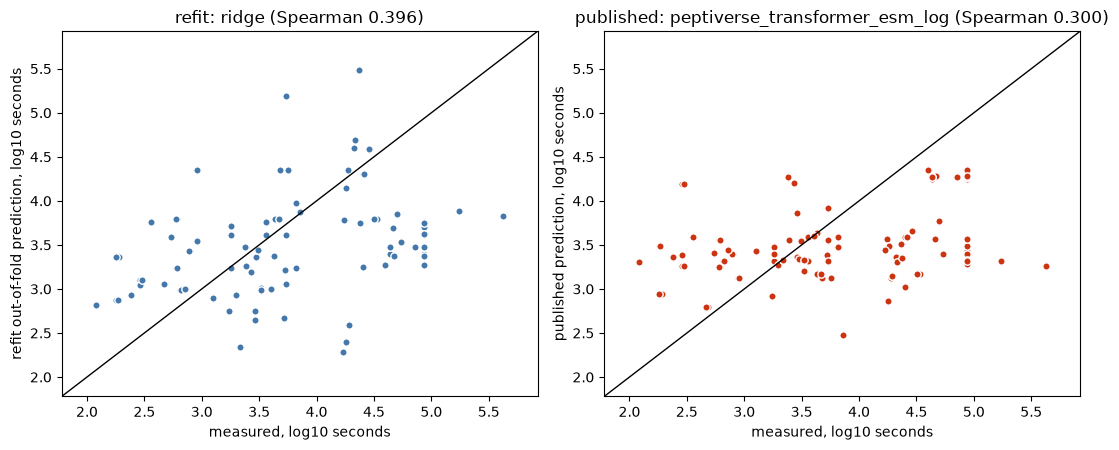

In [5]:
figure, axes = plt.subplots(1, 2, figsize=(11.0, 4.6))
best_refit = refit_metrics.loc[refit_metrics.estimator != "median_baseline"].sort_values("spearman_rho").iloc[-1]
column = f"predicted_{best_refit.estimator}"

axes[0].scatter(out_of_fold.measured_log10, out_of_fold[column], s=28, color="#4477AA", edgecolor="white")
limits = [out_of_fold.measured_log10.min() - 0.3, out_of_fold.measured_log10.max() + 0.3]
axes[0].plot(limits, limits, color="black", linewidth=1.0)
axes[0].set_xlim(limits); axes[0].set_ylim(limits)
axes[0].set_xlabel("measured, log10 seconds")
axes[0].set_ylabel("refit out-of-fold prediction, log10 seconds")
axes[0].set_title(f"refit: {best_refit.estimator} (Spearman {best_refit.spearman_rho:.3f})")

published_predictions = report.load_result(best_published.run, "predictions.csv", PRIMARY_COHORT)
axes[1].scatter(published_predictions.log10_half_life, published_predictions.predicted_log10_seconds,
                s=28, color="#CC3311", edgecolor="white")
axes[1].plot(limits, limits, color="black", linewidth=1.0)
axes[1].set_xlim(limits); axes[1].set_ylim(limits)
axes[1].set_xlabel("measured, log10 seconds")
axes[1].set_ylabel("published prediction, log10 seconds")
axes[1].set_title(f"published: {best_published.run} (Spearman {best_published.spearman_rho:.3f})")
figure.tight_layout()
display(figure)
plt.close("all")

## Does a refitted head react to a single substitution

A refit that reproduces half-life but ignores single substitutions is still unusable for
optimisation, so the refitted estimator is probed with the same exhaustive scans.

In [6]:
scans = refit.refit_sensitivity(embeddings, targets, clusters, cohort.sequence.tolist())
display(scans.style.format(precision=4).set_caption("Refitted ridge head: response to every single substitution"))
print(f"Median response over probes: {scans.median_absolute_delta_log10.median():.4f} log10")
print(f"Published artifacts for comparison, median response: "
      f"{summaries.scan_median_absolute_delta_log10.median():.4f} log10")

/home/max/repositories/pep-compass/assets/experiments/pcpsackm/datasets_analysis/test_models/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,parent,variants,parent_prediction_log10,median_absolute_delta_log10,max_absolute_delta_log10
0,GLAGIGILTV,190,4.6185,0.3673,1.5427
1,GLAGIGILTV,190,4.6185,0.3673,1.5427
2,YGGFL,95,3.5464,0.4511,2.0417
3,RRWQWR,114,3.6553,0.3741,1.4704
4,ELAGIGILTV,190,4.5370,0.3555,1.2493
5,GSSQSYGSGYSQSSG,285,3.4197,0.2178,1.5148


Median response over probes: 0.3673 log10
Published artifacts for comparison, median response: 0.0634 log10


## Conclusion of the refit experiment

Threshold statements on the numbers above.

In [7]:
baseline = refit_metrics.loc[refit_metrics.estimator == "median_baseline"].iloc[0]
best = refit_metrics.loc[refit_metrics.estimator != "median_baseline"].sort_values("spearman_rho").iloc[-1]

print(f"- Best refit on our cohort: {best.estimator}, Spearman {best.spearman_rho:.3f}, MAE {best.mae_log10:.3f} log10.")
print(f"- Median baseline on the same cohort: MAE {baseline.mae_log10:.3f} log10.")
print(f"- Best published artifact: {best_published.run}, Spearman {best_published.spearman_rho:.3f}, "
      f"MAE {best_published.mae_log10:.3f} log10.")
if best.spearman_rho > float(best_published.spearman_rho) + 0.1:
    print("- The frozen representation plus a small head is adequate on our data; the published")
    print("  training set, not the architecture, limits the published artifacts.")
elif best.spearman_rho < 0.3:
    print("- Refitting the published families on our cohort does not produce a usable predictor")
    print("  either, so a pooled sequence embedding is not sufficient for this task.")
else:
    print("- Refitting improves the result only marginally; neither the published artifact nor")
    print("  this architecture is ready for use as a stability oracle.")

- Best refit on our cohort: ridge, Spearman 0.396, MAE 0.725 log10.
- Median baseline on the same cohort: MAE 0.676 log10.
- Best published artifact: peptiverse_transformer_esm_log, Spearman 0.300, MAE 0.650 log10.
- Refitting improves the result only marginally; neither the published artifact nor
  this architecture is ready for use as a stability oracle.
